In [1]:
# Modified by Cursor
#%pip install -q "tensorflow>=2.16.0,<2.19.0" tf-keras "transformers>=4.46.0,<5.0.0" datasets scikit-learn matplotlib seaborn numpy accelerate safetensors

import re
import os
import random as _stdlib_random

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from datasets import ClassLabel, load_dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from transformers import (
    AutoTokenizer,
    DataCollatorWithPadding,
    TFAutoModelForSequenceClassification,
    create_optimizer,
)


def _patch_tf_keras_python312():
    """tf-keras calls randint(1, 1e9); Py3.12 requires integer bounds."""
    _orig_randint = _stdlib_random.Random.randint

    def _randint_int_bounds(self, a, b):
        return _orig_randint(self, int(a), int(b))

    if getattr(_stdlib_random.Random.randint, "__name__", "") != "_randint_int_bounds":
        _stdlib_random.Random.randint = _randint_int_bounds


_patch_tf_keras_python312()


def _unpack_tf_batch(batch):
    """prepare_tf_dataset yields (features_dict, labels), not a single dict."""
    if isinstance(batch, (tuple, list)) and len(batch) == 2:
        return batch[0], batch[1]
    labels = batch["labels"]
    model_inputs = {k: v for k, v in batch.items() if k != "labels"}
    return model_inputs, labels

c:\git\dai-ignite-adb\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_dir = "pan25-generative-ai-detection-task2-train"

train_path = os.path.join(data_dir, "train.jsonl")
test_path = os.path.join(data_dir, "dev.jsonl")

model_id = "FacebookAI/roberta-base"
label_order = [0, 1, 2, 3, 4, 5]
num_labels = len(label_order)
output_dir = "roberta_tf_pan_task2_runs"
os.makedirs(output_dir, exist_ok=True)

max_length = 512
batch_size = 8
num_epochs = 5
learning_rate = 2e-5
weight_decay = 0.01
warmup_ratio = 0.1
val_fraction = 0.05
random_seed = 1
early_stopping_patience = 2

# set true for pipeline smoke tests; false for full gpu training
debug_subset = True
debug_train_rows = 50
debug_val_rows = 50
debug_test_rows = 50

In [3]:
raw = load_dataset(
    "json",
    data_files={"train": train_path, "test": test_path},
)

print(raw)
print("train rows:", raw["train"].num_rows)
print("test rows:", raw["test"].num_rows)

DatasetDict({
    train: Dataset({
        features: ['text', 'language', 'label', 'source_dataset', 'model', 'label_text'],
        num_rows: 288918
    })
    test: Dataset({
        features: ['text', 'language', 'label', 'source_dataset', 'model', 'label_text'],
        num_rows: 72661
    })
})
train rows: 288918
test rows: 72661


In [4]:
def clean_text(text):
    text = str(text)
    text = text.replace("_SEP_", " ")
    text = text.replace("\n", " ")
    text = text.replace("\r", " ")
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text


def add_clean_text(batch):
    batch["text_clean"] = [clean_text(t) for t in batch["text"]]
    return batch


raw = raw.map(add_clean_text, batched=True, desc="clean text")


def cast_label(batch):
    batch["label"] = [int(x) for x in batch["label"]]
    return batch


raw = raw.map(cast_label, batched=True)

# required for stratified train_test_split in datasets
label_feature = ClassLabel(num_classes=num_labels, names=[str(i) for i in label_order])
raw = raw.cast_column("label", label_feature)

In [5]:
train_val = raw["train"].train_test_split(
    test_size=val_fraction,
    seed=random_seed,
    stratify_by_column="label",
)

ds_train = train_val["train"]
# datasets train_test_split names the holdout split "test", not "validation"
ds_val = train_val["test"]
ds_test = raw["test"]

if debug_subset:
    ds_train = ds_train.shuffle(seed=random_seed).select(range(min(debug_train_rows, len(ds_train))))
    ds_val = ds_val.shuffle(seed=random_seed).select(range(min(debug_val_rows, len(ds_val))))
    ds_test = ds_test.shuffle(seed=random_seed).select(range(min(debug_test_rows, len(ds_test))))

print("ds_train:", len(ds_train), "ds_val:", len(ds_val), "ds_test:", len(ds_test))

ds_train: 50 ds_val: 50 ds_test: 50


In [6]:
tokenizer = AutoTokenizer.from_pretrained(model_id)

def tokenize_batch(batch):
    return tokenizer(
        batch["text_clean"],
        truncation=True,
        max_length=max_length,
        padding=False,
    )

cols_to_drop = [c for c in ds_train.column_names if c not in ("label",)]
ds_train = ds_train.map(tokenize_batch, batched=True, remove_columns=cols_to_drop)
ds_val = ds_val.map(tokenize_batch, batched=True, remove_columns=cols_to_drop)
ds_test = ds_test.map(tokenize_batch, batched=True, remove_columns=cols_to_drop)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="tf")

In [7]:
id2label = {i: str(i) for i in label_order}
label2id = {str(i): i for i in label_order}

tf.keras.utils.set_random_seed(random_seed)

gpus = tf.config.list_physical_devices("GPU")
print("tensorflow:", tf.__version__)
print("gpus:", gpus)

model = TFAutoModelForSequenceClassification.from_pretrained(
    model_id,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    # safetensors PT->TF weight copy fails on some transformers builds; .bin works.
    use_safetensors=False,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro", labels=label_order, zero_division=0),
    }

train_batch_size = max(1, min(batch_size, len(ds_train)))
val_batch_size = max(1, min(batch_size, len(ds_val)))
test_batch_size = max(1, min(batch_size, len(ds_test)))

steps_per_epoch = max(1, int(np.ceil(len(ds_train) / train_batch_size)))
num_train_steps = steps_per_epoch * num_epochs
num_warmup_steps = int(num_train_steps * warmup_ratio)

optimizer, _ = create_optimizer(
    init_lr=learning_rate,
    num_train_steps=num_train_steps,
    num_warmup_steps=num_warmup_steps,
    weight_decay_rate=weight_decay,
)

loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(optimizer=optimizer, loss=loss, metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")])

# prepare_tf_dataset sets drop_remainder=shuffle by default; tiny debug splits need partial batches.
tf_train = model.prepare_tf_dataset(
    ds_train,
    shuffle=True,
    batch_size=train_batch_size,
    collate_fn=data_collator,
    drop_remainder=False,
)
tf_val = model.prepare_tf_dataset(
    ds_val,
    shuffle=False,
    batch_size=val_batch_size,
    collate_fn=data_collator,
    drop_remainder=False,
)
tf_test = model.prepare_tf_dataset(
    ds_test,
    shuffle=False,
    batch_size=test_batch_size,
    collate_fn=data_collator,
    drop_remainder=False,
)

class _TrainerState:
    def __init__(self):
        self.log_history = []


class HuggingFaceEvalCallback(tf.keras.callbacks.Callback):

    def __init__(self, keras_model, val_dataset, hf_val_dataset, metric_fn, state, monitor="eval_f1_macro"):
        super().__init__()
        self.keras_model = keras_model
        self.val_dataset = val_dataset
        self.hf_val_dataset = hf_val_dataset
        self.metric_fn = metric_fn
        self.state = state
        self.monitor = monitor
        self.best_weights = None
        self.best_monitor = -np.inf

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        epoch_num = epoch + 1
        self.state.log_history.append(
            {
                "epoch": epoch_num,
                "loss": float(logs.get("loss", np.nan)),
                "train_accuracy": float(logs.get("accuracy", np.nan)),
            }
        )

        val_loss = 0.0
        n_batches = 0
        for batch in self.val_dataset:
            model_inputs, labels = _unpack_tf_batch(batch)
            outputs = self.keras_model(model_inputs, training=False)
            batch_loss = loss(labels, outputs.logits)
            val_loss += float(batch_loss.numpy())
            n_batches += 1
        val_loss /= max(n_batches, 1)

        pred_output = self.keras_model.predict(self.val_dataset)
        logits = pred_output.logits if hasattr(pred_output, "logits") else pred_output
        labels_np = np.array(self.hf_val_dataset["label"])
        metrics = self.metric_fn((logits, labels_np))

        eval_entry = {
            "epoch": epoch_num,
            "eval_loss": val_loss,
            "eval_accuracy": metrics["accuracy"],
            "eval_f1_macro": metrics["f1_macro"],
        }
        self.state.log_history.append(eval_entry)
        print(
            f"epoch {epoch_num}: train_loss={logs.get('loss', float('nan')):.4f} "
            f"val_loss={val_loss:.4f} acc={metrics['accuracy']:.4f} f1_macro={metrics['f1_macro']:.4f}"
        )

        monitor_val = eval_entry[self.monitor]
        if monitor_val > self.best_monitor:
            self.best_monitor = monitor_val
            self.best_weights = self.keras_model.get_weights()

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.keras_model.set_weights(self.best_weights)


class EarlyStoppingOnEval(tf.keras.callbacks.Callback):
    def __init__(self, eval_callback, patience=2):
        super().__init__()
        self.eval_callback = eval_callback
        self.patience = patience
        self.wait = 0
        self.best = -np.inf

    def on_epoch_end(self, epoch, logs=None):
        eval_logs = [e for e in self.eval_callback.state.log_history if "eval_f1_macro" in e]
        if not eval_logs:
            return
        current = eval_logs[-1]["eval_f1_macro"]
        if current > self.best:
            self.best = current
            self.wait = 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                print(f"early stopping after epoch {epoch + 1}")
                self.model.stop_training = True


trainer_state = _TrainerState()
eval_callback = HuggingFaceEvalCallback(
    model,
    tf_val,
    ds_val,
    compute_metrics,
    trainer_state,
    monitor="eval_f1_macro",
)
early_stop = EarlyStoppingOnEval(eval_callback, patience=early_stopping_patience)

class _TrainerShim:
    def __init__(self, state, keras_model):
        self.state = state
        self.model = keras_model

    def predict(self, dataset):
        pred_batch_size = max(1, min(batch_size, len(dataset)))
        tf_ds = self.model.prepare_tf_dataset(
            dataset,
            shuffle=False,
            batch_size=pred_batch_size,
            collate_fn=data_collator,
            drop_remainder=False,
        )
        pred_output = self.model.predict(tf_ds)
        logits = pred_output.logits if hasattr(pred_output, "logits") else pred_output
        labels = np.array(dataset["label"])
        return type("PredictionOutput", (), {"predictions": logits, "label_ids": labels})()

    def save_model(self, save_dir):
        os.makedirs(save_dir, exist_ok=True)
        self.model.save_pretrained(save_dir)


trainer = _TrainerShim(trainer_state, model)

tensorflow: 2.18.1
gpus: []



TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

Some layers of TFRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [8]:
fit_history = model.fit(
    tf_train,
    epochs=num_epochs,
    callbacks=[eval_callback, early_stop],
    verbose=1,
)
train_result = {"history": fit_history.history, "log_history": trainer.state.log_history}
print(train_result)

Epoch 1/5

7/7 [==============================] - 26s 3s/steposs: 1.8148 - accurac
epoch 1: train_loss=1.8148 val_loss=1.7790 acc=0.2800 f1_macro=0.0729
7/7 [==============================] - 164s 19s/step - loss: 1.8148 - accuracy: 0.1800
Epoch 2/5
7/7 [==============================] - 23s 3s/steposs: 1.6854 - accurac
epoch 2: train_loss=1.6854 val_loss=1.6777 acc=0.2800 f1_macro=0.0729
7/7 [==============================] - 130s 19s/step - loss: 1.6854 - accuracy: 0.4000
Epoch 3/5
7/7 [==============================] - 22s 3s/steposs: 1.4514 - accurac
epoch 3: train_loss=1.4514 val_loss=1.5376 acc=0.2800 f1_macro=0.0729
early stopping after epoch 3
7/7 [==============================] - 124s 19s/step - loss: 1.4514 - accuracy: 0.4800
{'history': {'loss': [1.814794659614563, 1.6853599548339844, 1.4513620138168335], 'accuracy': [0.18000000715255737, 0.4000000059604645, 0.47999998927116394]}, 'log_history': [{'epoch': 1, 'loss': 1.814794659614563, 'train_accuracy': 0.18000000715255737}

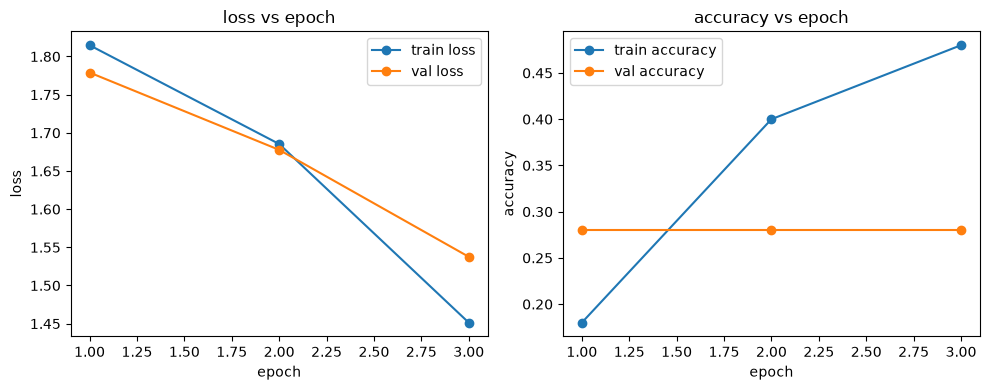

In [9]:
eval_logs = [entry for entry in trainer.state.log_history if "eval_loss" in entry]
epochs_eval = [int(entry["epoch"]) for entry in eval_logs]
eval_losses = [entry["eval_loss"] for entry in eval_logs]
eval_accs = [entry.get("eval_accuracy", np.nan) for entry in eval_logs]

epoch_to_train_loss = {}
epoch_to_train_acc = {}
for entry in trainer.state.log_history:
    if "loss" in entry and "eval_loss" not in entry and "epoch" in entry:
        epoch_to_train_loss[int(entry["epoch"])] = entry["loss"]
        if "train_accuracy" in entry:
            epoch_to_train_acc[int(entry["epoch"])] = entry["train_accuracy"]
train_losses = [epoch_to_train_loss.get(epoch, np.nan) for epoch in epochs_eval]
train_accs = [epoch_to_train_acc.get(epoch, np.nan) for epoch in epochs_eval]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(epochs_eval, train_losses, marker="o", label="train loss")
axes[0].plot(epochs_eval, eval_losses, marker="o", label="val loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("loss vs epoch")
axes[0].legend()

axes[1].plot(epochs_eval, train_accs, marker="o", label="train accuracy")
axes[1].plot(epochs_eval, eval_accs, marker="o", label="val accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].set_title("accuracy vs epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
predictions = trainer.predict(ds_test)
y_pred = np.argmax(predictions.predictions, axis=-1)
y_true = predictions.label_ids

7/7 [==============================] - 21s 3s/step


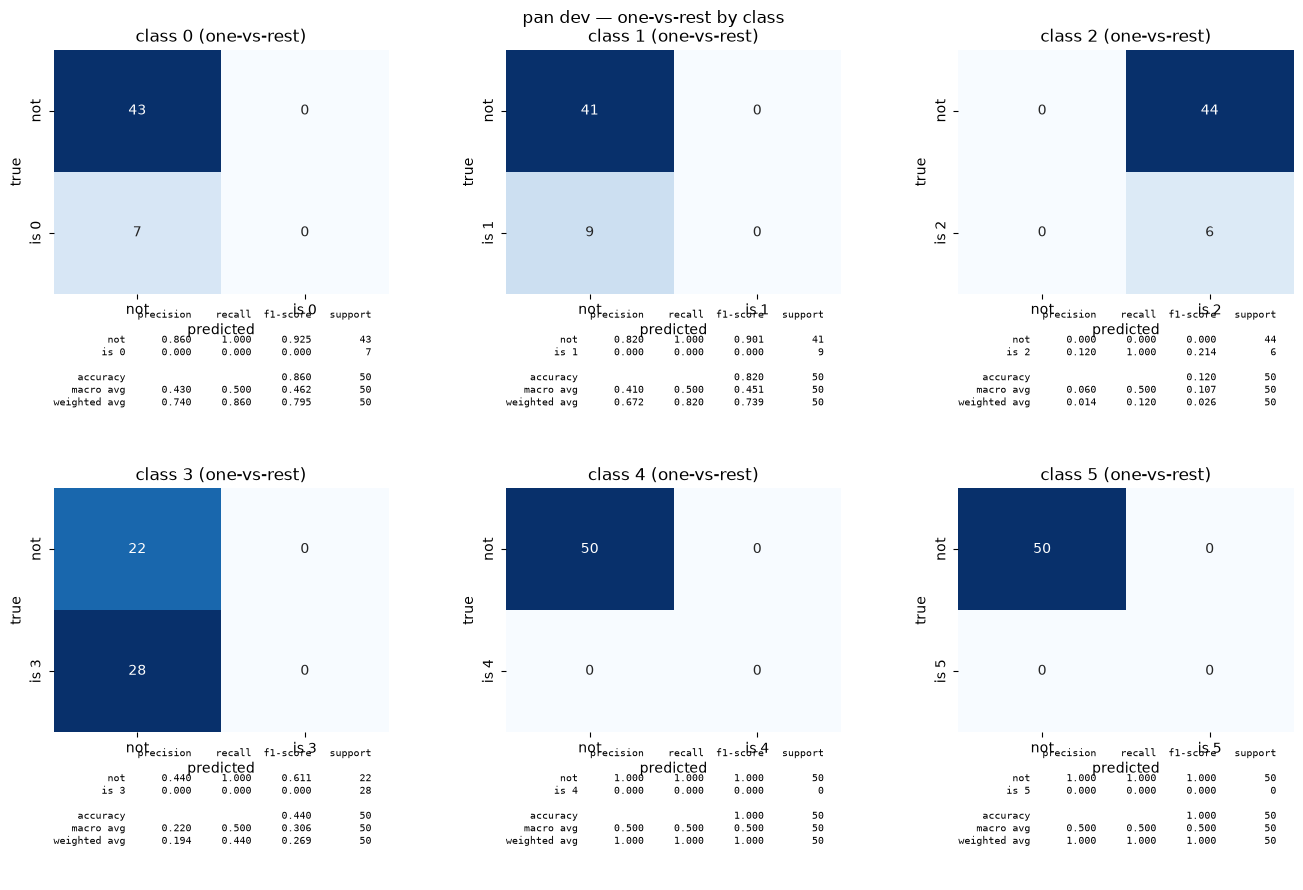

In [11]:
fig = plt.figure(figsize=(16, 10))
outer = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[1, 1], hspace=0.12)

for block, labels_in_block in enumerate([label_order[:3], label_order[3:]]):
    inner = gridspec.GridSpecFromSubplotSpec(
        2,
        3,
        subplot_spec=outer[block],
        height_ratios=[2.2, 1.2],
        hspace=0.08,
        wspace=0.35,
    )

    for col, label in enumerate(labels_in_block):
        ax_cm = fig.add_subplot(inner[0, col])
        ax_report = fig.add_subplot(inner[1, col])

        y_true_bin = (y_true == label).astype(int)
        y_pred_bin = (y_pred == label).astype(int)
        cm = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1])

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=["not", f"is {label}"],
            yticklabels=["not", f"is {label}"],
            ax=ax_cm,
        )
        ax_cm.set_xlabel("predicted")
        ax_cm.set_ylabel("true")
        ax_cm.set_title(f"class {label} (one-vs-rest)")

        report_str = classification_report(
            y_true_bin,
            y_pred_bin,
            labels=[0, 1],
            target_names=["not", f"is {label}"],
            digits=3,
            zero_division=0,
        )
        ax_report.axis("off")
        ax_report.text(
            0.0,
            1.0,
            report_str,
            transform=ax_report.transAxes,
            va="top",
            ha="left",
            fontsize=7.5,
            family="monospace",
        )

plt.suptitle("pan dev — one-vs-rest by class", y=0.98)
fig.subplots_adjust(top=0.94)
plt.show()

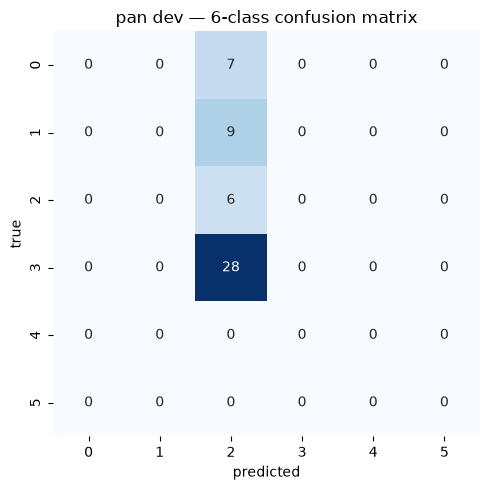

              precision    recall  f1-score   support

           0      0.000     0.000     0.000         7
           1      0.000     0.000     0.000         9
           2      0.120     1.000     0.214         6
           3      0.000     0.000     0.000        28
           4      0.000     0.000     0.000         0
           5      0.000     0.000     0.000         0

    accuracy                          0.120        50
   macro avg      0.020     0.167     0.036        50
weighted avg      0.014     0.120     0.026        50



In [12]:
cm_full = confusion_matrix(y_true, y_pred, labels=label_order)

fig, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(
    cm_full,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=label_order,
    yticklabels=label_order,
    ax=ax,
)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("pan dev — 6-class confusion matrix")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_true,
        y_pred,
        labels=label_order,
        digits=3,
        zero_division=0,
    )
)

In [13]:
# save_dir = "roberta_tf_pan_task2_checkpoint"
# trainer.save_model(save_dir)
# tokenizer.save_pretrained(save_dir)